# 1. Kernel Density Estimation for Foreground Detection

In [1]:
# Imports necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
import os
import shutil
import math
import nbformat

import cv2
import cupy as cp

from collections import Counter
from typing import List, Tuple, Dict, Optional, Union, Any
from tqdm import tqdm

device_id = cp.cuda.runtime.getDevice()
device_props = cp.cuda.runtime.getDeviceProperties(device_id)
print("GPU Name:", device_props['name'].decode('utf-8'))

# 1. Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = cp.random.default_rng(seed)
cp.random.seed(seed) 

# 3. Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="magma_r", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    """Helper function for plotting."""
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.text(0.98, -0.01, userid, ha="right", va="bottom",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.tight_layout()
    plt.show()

print("Setup complete.")

GPU Name: NVIDIA GeForce GTX 1650
Seed generated: 1027714457
Setup complete.


## 1.1 Image Pre-Processing

I chose RGB channels as the main features to examine since the colour palettes between background and foreground are distinct. The background is mainly green and grey, while the foreground *(person)* consists of light pinks and skin tones.

I subtracted both images and got a ground truth set to base my accuracy metric for different sweeps. This is a crude approximation since the given images are not the same, which leads to noise and discrepancies that I've tried to fix with simple erosion.

I resized the image as follows:
$$ D_{new} = D_{1}+D_{2}+0.5\cdot (D_2+D_1) $$

Images resized to: (500, 570, 3)
Background features shape: (285000, 3)
Test features shape: (285000, 3)


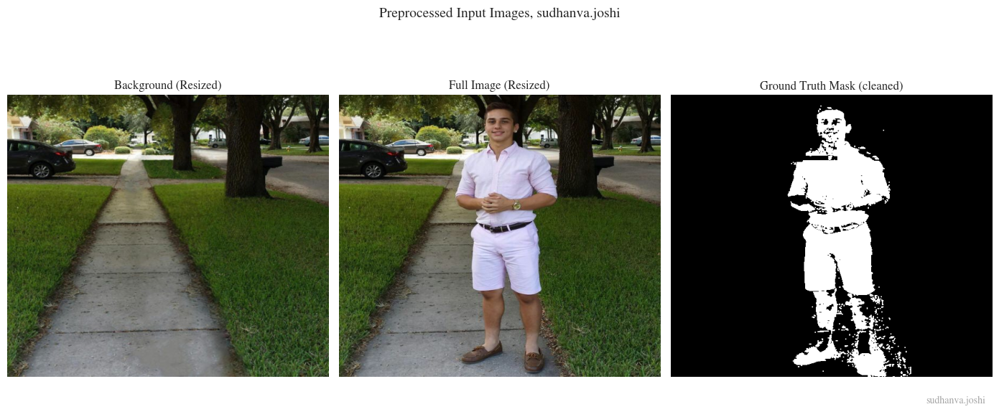

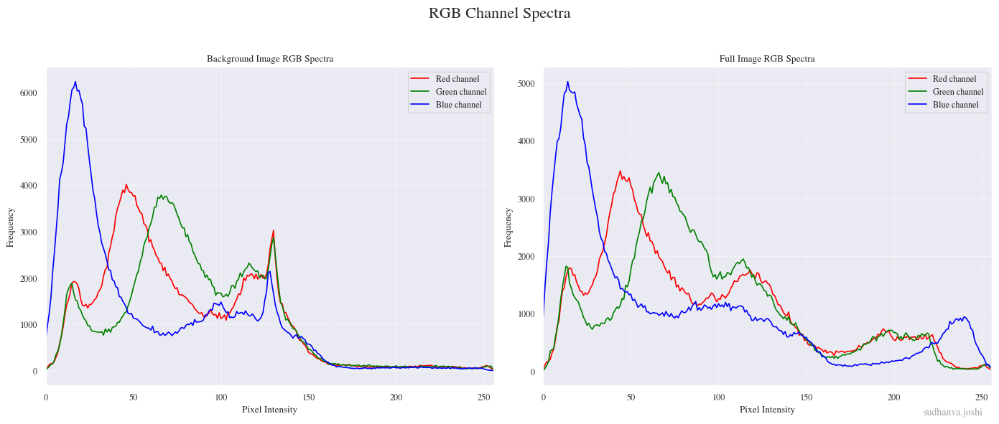

In [2]:
RESIZE_DIM = (570, 500)
IMG_SHAPE = (RESIZE_DIM[1], RESIZE_DIM[0]) # (height, width)

def load_and_preprocess(bg_path = "./data/Q1/back.jpg", 
                        test_path = "./data/Q1/full.jpg", 
                        resize_dim=RESIZE_DIM):
    """
    Loads, resizes, and feature-extracts background and test images.

    Args:
        bg_path (str): Path to the background image.
        test_path (str): Path to the test image.
        resize_dim (tuple): The (width, height) to resize images to.

    Returns:
        tuple: (
            bg_img_resized (cp.ndarray),
            test_img_resized (cp.ndarray),
            bg_features (cp.ndarray),
            test_features (cp.ndarray)
        )
    """
    # 1. Load images
    bg_img = cv2.imread(bg_path)
    test_img = cv2.imread(test_path)

    if bg_img is None or test_img is None:
        raise FileNotFoundError(f"Could not load images. Check paths: {bg_path}, {test_path}")

    # 2. Image Alignment and Resizing
    bg_img_resized = cv2.resize(bg_img, resize_dim, interpolation=cv2.INTER_AREA)
    test_img_resized = cv2.resize(test_img, resize_dim, interpolation=cv2.INTER_AREA)

    # 3. Convert from BGR (cv2 default) to RGB
    bg_img_rgb = cv2.cvtColor(bg_img_resized, cv2.COLOR_BGR2RGB)
    test_img_rgb = cv2.cvtColor(test_img_resized, cv2.COLOR_BGR2RGB)

    # 4. Feature Extraction (RGB)
    bg_features = bg_img_rgb.reshape(-1, 3)
    test_features = test_img_rgb.reshape(-1, 3)
    
    # 5. Normalize features to [0, 1] for stable KDE
    bg_features_norm = cp.asarray(bg_features, dtype=cp.float32) / 255.0
    test_features_norm = cp.asarray(test_features, dtype=cp.float32) / 255.0

    return bg_img_rgb, test_img_rgb, bg_features_norm, test_features_norm

def plot_image(img, title, ax, cmap=None):
    """Helper function to plot an image with title and username."""
    ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=12)
    ax.axis('off')

# Metric: Intersection over Union (IoU)
def calculate_iou(gt_mask, pred_mask):
    """Calculates Intersection over Union (IoU) using CuPy."""
    intersection = cp.sum(gt_mask & pred_mask)
    union = cp.sum(gt_mask | pred_mask)
    
    if union == 0:
        return 0.0  # Avoid division by zero
    
    iou = intersection / union
    return iou

# Load and preprocess images
bg_img, test_img, bg_features, test_features = load_and_preprocess()

print(f"Images resized to: {bg_img.shape}")
print(f"Background features shape: {bg_features.shape}")
print(f"Test features shape: {test_features.shape}")

diff = cv2.absdiff(bg_img, test_img)
gray_diff = cv2.cvtColor(diff, cv2.COLOR_RGB2GRAY)
_, gt_mask_np = cv2.threshold(gray_diff, 25, 255, cv2.THRESH_BINARY)  # uint8 (0 or 255)
kernel_open = np.ones((2, 2), np.uint8)  
gt_mask_clean = cv2.morphologyEx(gt_mask_np, cv2.MORPH_OPEN, kernel_open, iterations=1)
gt_mask_bool = (gt_mask_clean > 0)  
gt_mask_gpu = cp.asarray(gt_mask_bool) 

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
plot_image(bg_img, "Background (Resized)", axes[0])
plot_image(test_img, "Full Image (Resized)", axes[1])

plot_image((gt_mask_bool.astype(np.uint8) * 255), "Ground Truth Mask (cleaned)", axes[2], cmap='gray')
plt.suptitle(f"Preprocessed Input Images, {username}", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.text(0.98, -0.1, username, ha="right", va="bottom",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
plt.show()


fig_spectra, axes_spectra = plt.subplots(1, 2, figsize=(14, 6))

colors = ('r', 'g', 'b')
labels = ('Red', 'Green', 'Blue')

axes_spectra[0].set_title('Background Image RGB Spectra')
axes_spectra[0].set_xlabel('Pixel Intensity')
axes_spectra[0].set_ylabel('Frequency')
for i, color in enumerate(colors):
    hist, bin_edges = np.histogram(bg_img[:, :, i].ravel(), bins=256, range=[0, 256])
    axes_spectra[0].plot(hist, color=color, label=f'{labels[i]} channel')
axes_spectra[0].legend()
axes_spectra[0].grid(True, linestyle='--', alpha=0.6)
axes_spectra[0].set_xlim([0, 256])

axes_spectra[1].set_title('Full Image RGB Spectra')
axes_spectra[1].set_xlabel('Pixel Intensity')
axes_spectra[1].set_ylabel('Frequency')

for i, color in enumerate(colors):
    hist, bin_edges = np.histogram(test_img[:, :, i].ravel(), bins=256, range=[0, 256])
    axes_spectra[1].plot(hist, color=color, label=f'{labels[i]} channel')

axes_spectra[1].legend()
axes_spectra[1].grid(True, linestyle='--', alpha=0.6)
axes_spectra[1].set_xlim([0, 256])
plt.suptitle('RGB Channel Spectra', fontsize=16)
plt.text(0.98, -0.1, username, ha="right", va="bottom",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
plt.tight_layout(rect=[0, 0, 1, 0.95])

## 1.2 Custom KDE Class Implementation

In [3]:
class KDE:
    """
    Implements Kernel Density Estimation from scratch using only numpy. 
    """
    def __init__(self, kernel='gaussian', bandwidth=1.0):
        """
        Initializes the KDE model.

        Args:
            kernel (str): Kernel type ('gaussian', 'triangular', 'uniform').
            bandwidth (float): The bandwidth parameter 'h'.
        """
        self.kernel = kernel
        self.bandwidth = bandwidth
        self.data = None  # To store background training data
        self.n_data = 0
        self.d_features = 0

    def _kernel_gaussian(self, u):
        """
        Multivariate Gaussian kernel (product of 1D Gaussians).
        K(u) = (1 / (2*pi)^(d/2)) * exp(-0.5 * ||u||^2)
        """
        # u shape: (batch_size, n_data, d)
        norm_sq = cp.sum(u**2, axis=2) # (batch_size, n_data)
        const = (1.0 / (cp.sqrt(2 * cp.pi)**self.d_features))
        return const * cp.exp(-0.5 * norm_sq)

    def _kernel_triangular(self, u):
        """
        Multivariate Triangular kernel (product of 1D).
        K_1D(u_j) = max(0, 1 - |u_j|)
        """
        # u shape: (batch_size, n_data, d)
        abs_u = cp.abs(u)
        k_1d = cp.maximum(0, 1 - abs_u) # (batch_size, n_data, d)
        return cp.prod(k_1d, axis=2) # (batch_size, n_data)

    def _kernel_uniform(self, u):
        """
        Multivariate Uniform ('box') kernel (product of 1D).
        K_1D(u_j) = 0.5 if |u_j| <= 1, else 0
        """
        # u shape: (batch_size, n_data, d)
        abs_u = cp.abs(u)
        k_1d = 0.5 * (abs_u <= 1).astype(cp.float32) # (batch_size, n_data, d)
        return cp.prod(k_1d, axis=2) # (batch_size, n_data)

    def fit(self, data, sample_size=1000):
        """
        Fits the KDE to the background data.
        Implements smart sampling to reduce computational cost. 

        Args:
            data (cp.ndarray): Training data (e.g., background features).
            sample_size (int): Number of samples to randomly select from data.
        """
        self.d_features = data.shape[1] # Feature dimensionality

        # Smart sampling strategy: Random subset selection
        if data.shape[0] > sample_size:
            indices = cp.random.choice(data.shape[0], sample_size, replace=False)
            self.data = data[indices]
        else:
            self.data = data
            
        self.n_data = self.data.shape[0]
        print(f"KDE fitted with {self.n_data} samples, {self.d_features} features.")

    def predict(self, samples, batch_size=512):
        """
        Estimates the probability density for given samples.
        Uses vectorized, batched operations for efficiency.

        Args:
            samples (cp.ndarray): Test samples (e.g., test image features).
            batch_size (int): How many samples to process at once.

        Returns:
            cp.ndarray: Estimated densities for each sample.
        """
        n_samples = samples.shape[0]
        densities = cp.zeros(n_samples)
        h = self.bandwidth
        d = self.d_features
        n_bg = self.n_data

        if self.data is None:
            raise RuntimeError("Model must be 'fit' before 'predict'.")

        # Choose kernel function
        if self.kernel == 'gaussian':
            kernel_func = self._kernel_gaussian
        elif self.kernel == 'triangular':
            kernel_func = self._kernel_triangular
        elif self.kernel == 'uniform':
            kernel_func = self._kernel_uniform
        else:
            raise ValueError(f"Unknown kernel type: {self.kernel}")

        # Process in batches to save memory
        n_batches = int(cp.ceil(n_samples / batch_size))
        
        for i in tqdm(range(n_batches), desc=f"Predicting (k={self.kernel}, bw={h})"):
            start = i * batch_size
            end = min((i + 1) * batch_size, n_samples)
            batch = samples[start:end] # (batch_size, d)

            # Vectorized computation using broadcasting:
            # batch:      (batch_size, 1, d)
            # self.data:  (1, n_data, d)
            # diff:       (batch_size, n_data, d)
            diff = batch[:, cp.newaxis, :] - self.data[cp.newaxis, :, :]
            u = diff / h # (batch_size, n_data, d)

            # Calculate kernel values
            k_values = kernel_func(u) # (batch_size, n_data)
            
            # Sum over all background samples
            sum_k = cp.sum(k_values, axis=1) # (batch_size,)

            # Apply the full KDE formula 
            # f(x) = (1 / (n * h^d)) * sum(K(u_i))
            densities[start:end] = sum_k / (n_bg * (h**d))

        return densities

## 1.3 Foreground Detection

Some runs marked the entire image as *background* due to the bandwidth being too large/small, which causes excessive pixel values to be assigned to background/foreground, causing them to spike above the threshold.



Starting KDE Parameter Sweep.
Image Size: (500, 570), KDE Sample Size: 5000


Testing: k=gaussian, bw=0.01
KDE fitted with 5000 samples, 3 features.


Predicting (k=gaussian, bw=0.01): 100%|██████████| 557/557 [00:15<00:00, 36.30it/s]


Result for k=gaussian, bw=0.01: IoU = 0.5899


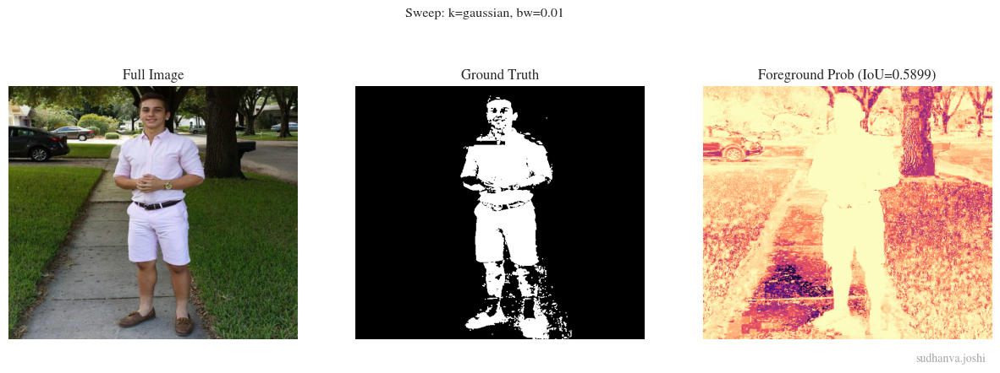


Testing: k=gaussian, bw=0.05
KDE fitted with 5000 samples, 3 features.


Predicting (k=gaussian, bw=0.05): 100%|██████████| 557/557 [00:15<00:00, 36.31it/s]


Result for k=gaussian, bw=0.05: IoU = 0.5702


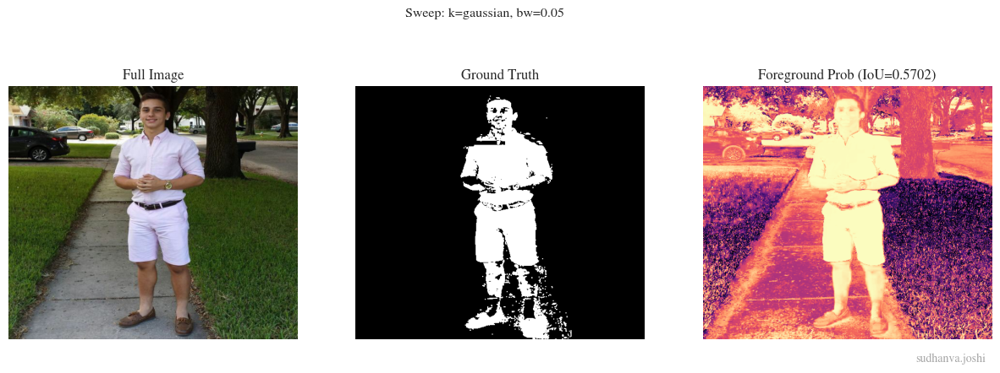


Testing: k=gaussian, bw=0.1
KDE fitted with 5000 samples, 3 features.


Predicting (k=gaussian, bw=0.1): 100%|██████████| 557/557 [00:15<00:00, 36.32it/s]


Result for k=gaussian, bw=0.1: IoU = 0.5390


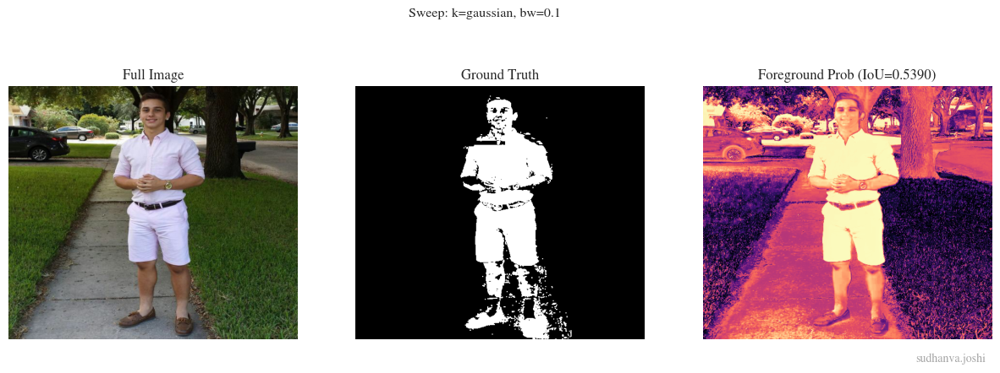


Testing: k=gaussian, bw=0.2
KDE fitted with 5000 samples, 3 features.


Predicting (k=gaussian, bw=0.2): 100%|██████████| 557/557 [00:15<00:00, 36.31it/s]


Result for k=gaussian, bw=0.2: IoU = 0.4744


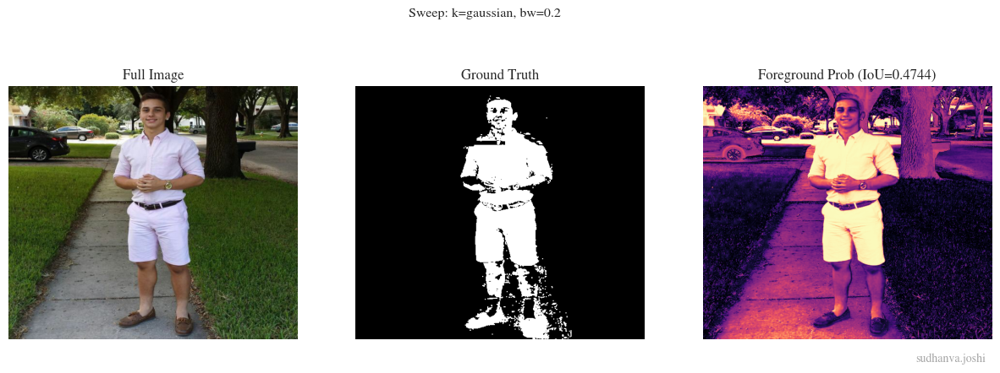


Testing: k=triangular, bw=0.01
KDE fitted with 5000 samples, 3 features.


Predicting (k=triangular, bw=0.01): 100%|██████████| 557/557 [00:14<00:00, 38.66it/s] 


Result for k=triangular, bw=0.01: IoU = 0.0000


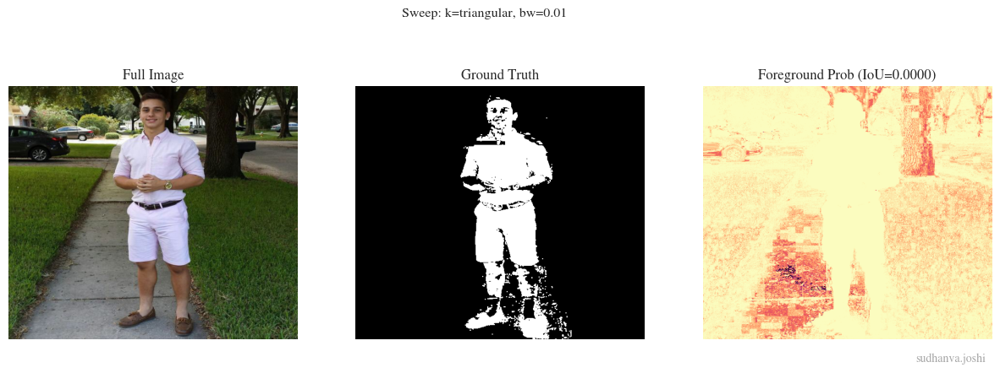


Testing: k=triangular, bw=0.05
KDE fitted with 5000 samples, 3 features.


Predicting (k=triangular, bw=0.05): 100%|██████████| 557/557 [00:14<00:00, 38.66it/s] 


Result for k=triangular, bw=0.05: IoU = 0.5822


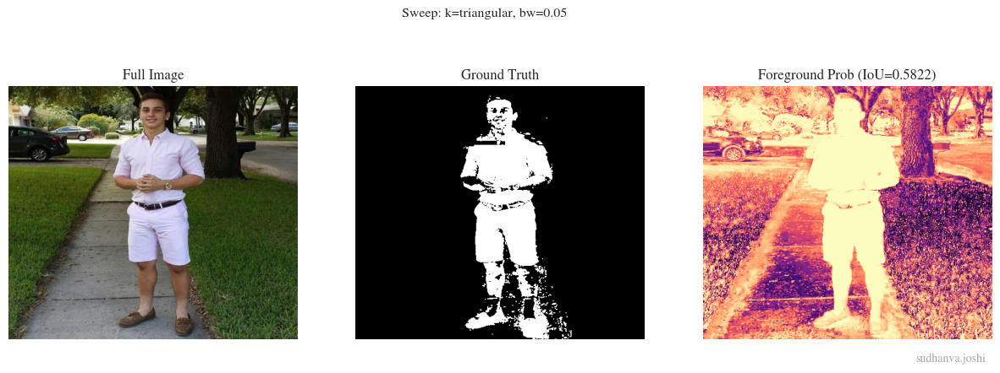


Testing: k=triangular, bw=0.1
KDE fitted with 5000 samples, 3 features.


Predicting (k=triangular, bw=0.1): 100%|██████████| 557/557 [00:14<00:00, 38.66it/s] 


Result for k=triangular, bw=0.1: IoU = 0.5743


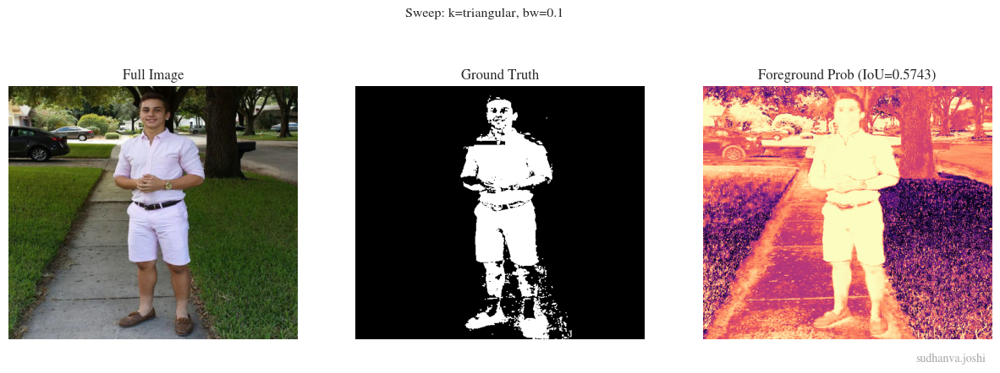


Testing: k=triangular, bw=0.2
KDE fitted with 5000 samples, 3 features.


Predicting (k=triangular, bw=0.2): 100%|██████████| 557/557 [00:14<00:00, 38.66it/s] 


Result for k=triangular, bw=0.2: IoU = 0.5455


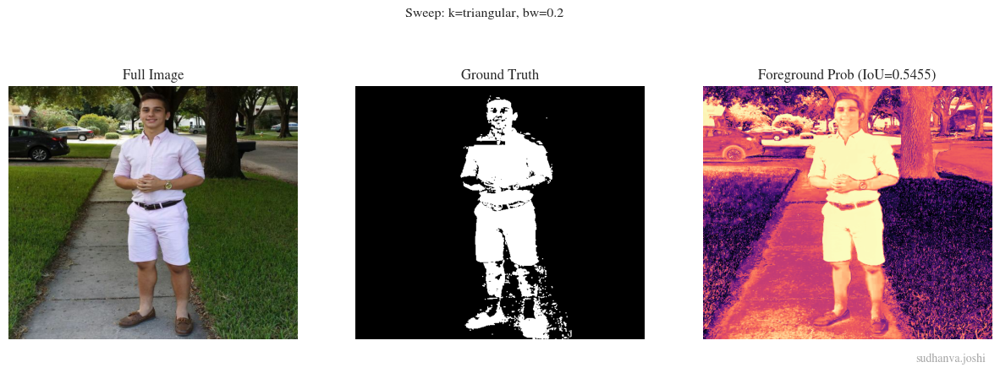


Testing: k=uniform, bw=0.01
KDE fitted with 5000 samples, 3 features.


Predicting (k=uniform, bw=0.01): 100%|██████████| 557/557 [00:14<00:00, 37.34it/s] 


Result for k=uniform, bw=0.01: IoU = 0.0000


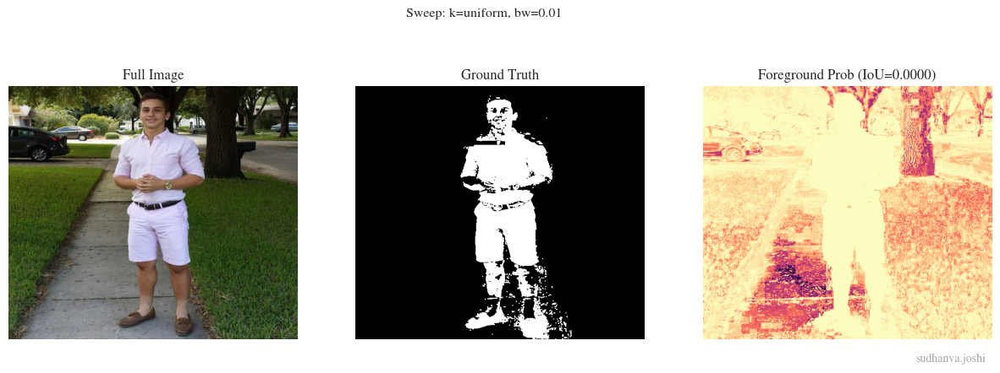


Testing: k=uniform, bw=0.05
KDE fitted with 5000 samples, 3 features.


Predicting (k=uniform, bw=0.05): 100%|██████████| 557/557 [00:14<00:00, 37.34it/s] 


Result for k=uniform, bw=0.05: IoU = 0.5814


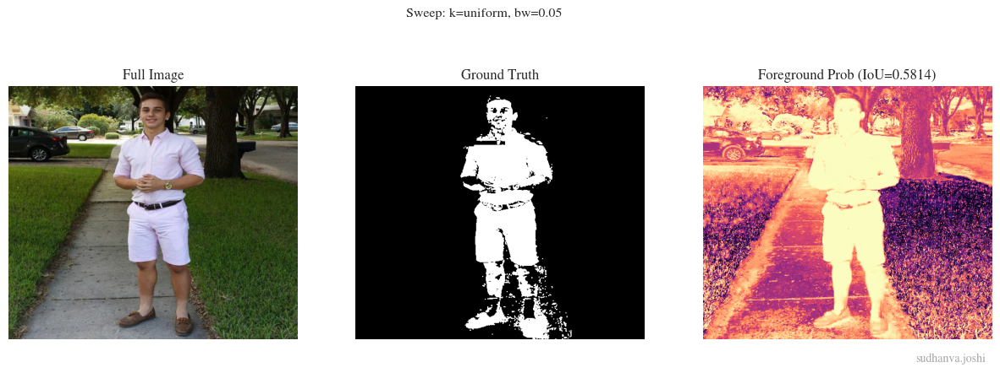


Testing: k=uniform, bw=0.1
KDE fitted with 5000 samples, 3 features.


Predicting (k=uniform, bw=0.1): 100%|██████████| 557/557 [00:14<00:00, 37.33it/s] 


Result for k=uniform, bw=0.1: IoU = 0.5678


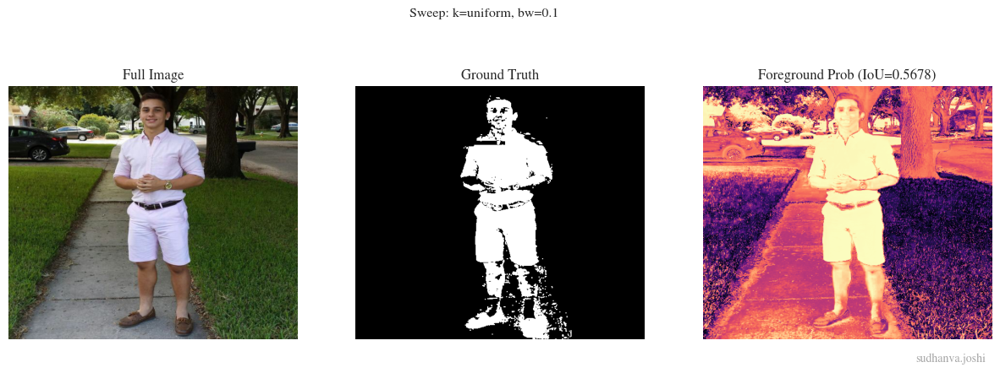


Testing: k=uniform, bw=0.2
KDE fitted with 5000 samples, 3 features.


Predicting (k=uniform, bw=0.2): 100%|██████████| 557/557 [00:14<00:00, 37.34it/s] 


Result for k=uniform, bw=0.2: IoU = 0.4814


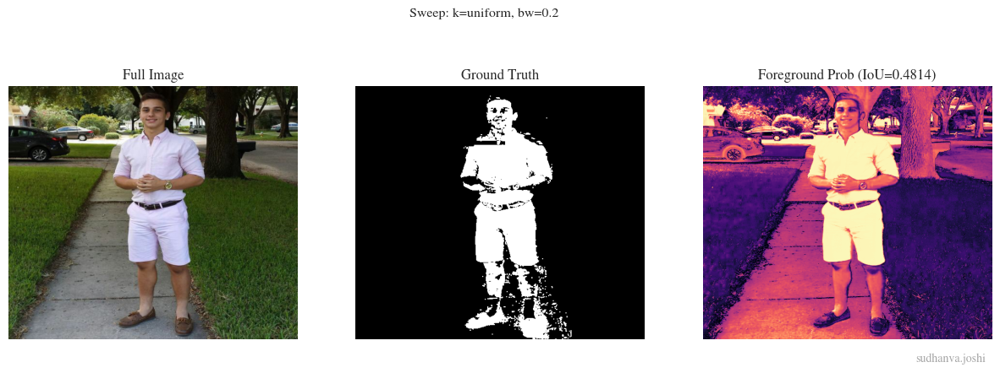


Sweep Complete

Sweep Results (Intersection over Union - IoU):
|   bandwidth |   gaussian |   triangular |   uniform |
|------------:|-----------:|-------------:|----------:|
|      0.0100 |     0.5899 |       0.0000 |    0.0000 |
|      0.0500 |     0.5702 |       0.5822 |    0.5814 |
|      0.1000 |     0.5390 |       0.5743 |    0.5678 |
|      0.2000 |     0.4744 |       0.5455 |    0.4814 |

Displaying best result with IoU: 0.5899


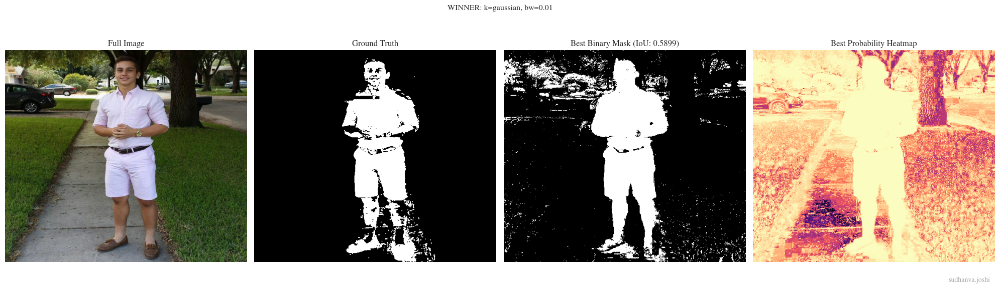

In [4]:
# Run Sweeps
kernels_to_test = ["gaussian", "triangular", "uniform"]
bandwidths_to_test = [0.01, 0.05, 0.1, 0.2]
SAMPLE_SIZE = 5000
THRESHOLD_PERCENTILE = 5.0

results = []
best_iou = -1
best_foreground_map = None
best_binary_mask = None 
best_params = {}

print(f"Starting KDE Parameter Sweep.")
print(f"Image Size: {IMG_SHAPE}, KDE Sample Size: {SAMPLE_SIZE}\n")

for kernel in kernels_to_test:
    for bandwidth in bandwidths_to_test:
        params_str = f"k={kernel}, bw={bandwidth}"
        print(f"\nTesting: {params_str}")
        
        # 1. Initialize and Fit KDE on BACKGROUND
        kde = KDE(kernel=kernel, bandwidth=bandwidth)
        kde.fit(bg_features, sample_size=SAMPLE_SIZE)
        
        # 2. Find Threshold
        bg_densities = kde.predict(bg_features)
        threshold = cp.percentile(bg_densities, THRESHOLD_PERCENTILE)
        
        # 3. Predict
        test_densities = kde.predict(test_features)
        
        # 4. Classify (The Binary Mask)
        pred_mask_gpu_flat = test_densities < threshold
        pred_mask_gpu = pred_mask_gpu_flat.reshape(IMG_SHAPE)
        
        # Calculate IoU
        iou = calculate_iou(gt_mask_gpu, pred_mask_gpu)
        iou_cpu = iou.get() 
        
        print(f"Result for {params_str}: IoU = {iou_cpu:.4f}")
        
        # 5. Visualization prep
        raw_density_map = test_densities.get().reshape(IMG_SHAPE)
        gt_mask_np_cpu = gt_mask_gpu.get() 
        
        # Normalize and Invert for Heatmap
        d_min, d_max = raw_density_map.min(), raw_density_map.max()
        density_norm = (raw_density_map - d_min) / (d_max - d_min + 1e-8)
        foreground_map = 1.0 - density_norm 
        
        # --- PLOT EVERY ITERATION (Image, GT, Heatmap) ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        plot_image(test_img, "Full Image", axes[0])
        plot_image(gt_mask_np_cpu, "Ground Truth", axes[1], cmap='gray')
        plot_image(foreground_map, 
                   f"Foreground Prob (IoU={iou_cpu:.4f})", 
                   axes[2], cmap='magma')

        plt.suptitle(f"Sweep: {params_str}")
        plt.text(0.98, -0.1, username, ha="right", va="bottom",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
        plt.show()
        # -------------------------------------------------
        
        results.append({
            "kernel": kernel,
            "bandwidth": bandwidth,
            "iou": iou_cpu
        })
        
        # 6. Save Best Result
        if iou_cpu > best_iou:
            best_iou = iou_cpu
            best_foreground_map = foreground_map
            best_binary_mask = pred_mask_gpu.get() # Save mask only for the best
            best_params = {"kernel": kernel, "bandwidth": bandwidth}

print("\nSweep Complete")

results_df = pd.DataFrame(results)
print("\nSweep Results (Intersection over Union - IoU):")
print(results_df.pivot(index="bandwidth", columns="kernel", values="iou").to_markdown(floatfmt=".4f"))

print(f"\nDisplaying best result with IoU: {best_iou:.4f}")

# --- FINAL PLOT (Image, GT, Binary Mask, Heatmap) ---
gt_mask_np = gt_mask_gpu.get() 

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

# 1. Original
plot_image(test_img, "Full Image", axes[0])

# 2. Ground Truth
plot_image(gt_mask_np, "Ground Truth", axes[1], cmap='gray')

# 3. Predicted Binary Mask (Only shown for the best one)
plot_image(best_binary_mask.astype(np.uint8) * 255, 
           f"Best Binary Mask (IoU: {best_iou:.4f})", 
           axes[2], cmap='gray')

# 4. Probability Heatmap
plot_image(best_foreground_map, 
           "Best Probability Heatmap", 
           axes[3], cmap='magma')

plt.text(0.98, -0.1, username, ha="right", va="bottom",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
plt.suptitle(f"WINNER: k={best_params['kernel']}, bw={best_params['bandwidth']}")
plt.tight_layout()
plt.show()